# Chapter 3: Polynomial Regression excercise

In [41]:
%reset
low_memory=False

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

## 3.1 Introduction & Motivation

While linear regression in itself is an interesting tool, it can only bring us so far. At a certain point data will no longer have a linear connection and we will have to resort to using **polynomial regression**. Using an example regarding cars we will compare both forms of regression and try to end up with the best model possible.

## 3.2 Problem setting

Every car has a certain distance it can drive per unit of fuel. In the industry, this is measured in **MPG** (or Miles Per Gallon). The higher the MPG, the more fuel-efficient a certain car is. Generally speaking we want a high MPG to save money on fuel cost.

## 3.3 Model

Go to canvas and donload the file "Auto.csv" from module 3. This data contains the required dataset.

In [42]:
df = pd.read_csv("Auto.csv")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


##### Question 1: Have a look at the data. Can you spot a column we will not be able to use? Why is this? Can you think of a way to transform this type of data so we could use it after all? Would work for the data we currently have? Elaborate.

We kunnen de kolom "car name" niet gebruiken omdat deze tekst bevat.

Machine learning modellen zoals linear regression werken alleen met numerieke waarden. 
De kolom "car name" is een categorische variabele en moet eerst omgezet worden naar getallen via encoding (bijvoorbeeld one-hot encoding).

Dit zou echter veel extra kolommen creëren en is niet relevant voor het voorspellen van MPG. Daarom verwijderen we deze kolom.

##### Question 2: Drop the extra column. Create a train_test split from the remaining data. Make sure **not** to include the final mpg colum in your "X" dataset!

In [43]:
# Kolom verwijderen
df_model = df.drop("car name", axis=1)

# Features en target definiëren
X = df_model.drop("mpg", axis=1)
y = df_model["mpg"]

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (318, 7)
Test shape: (80, 7)


Since we are working with a lot of variables, it is time to plot a heatmap.

##### Question 3: Explore the heatmap. Which variables would you expect to be useful when trying to predict MPG?

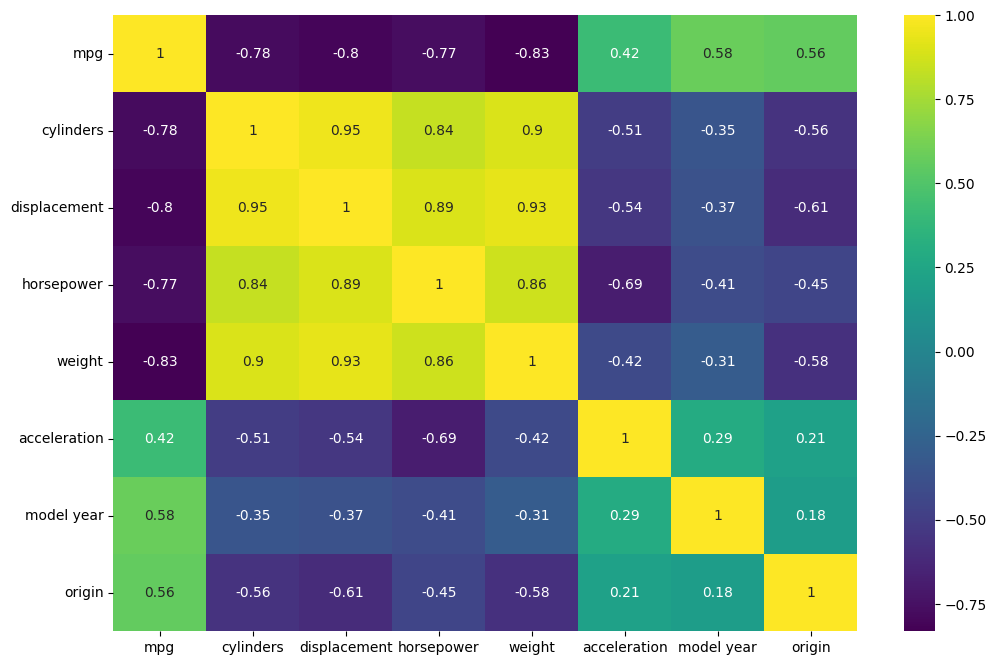

In [44]:
plt.figure(figsize=(12,8))
sns.heatmap(df_model.corr(), annot=True, cmap="viridis")
plt.show()

De variabelen met de sterkste correlatie met MPG zijn:

- weight (sterke negatieve correlatie)
- horsepower (negatieve correlatie)
- displacement (negatieve correlatie)

Dit betekent dat zwaardere auto's, auto's met meer horsepower en grotere motoren meestal een lagere MPG hebben.

Weight lijkt de belangrijkste voorspeller.

##### Question 4: Plot the data using "weight" as the independant variable and 'MPG' as the dependant variable. Fit a model using linear regression. Calculate $R^2$ and the MSE. Is this any good? Show the model on a plot and elaborate.

MPG = 46.7821 + (-0.007805 × weight)
R² = 0.7230
MSE = 14.8949


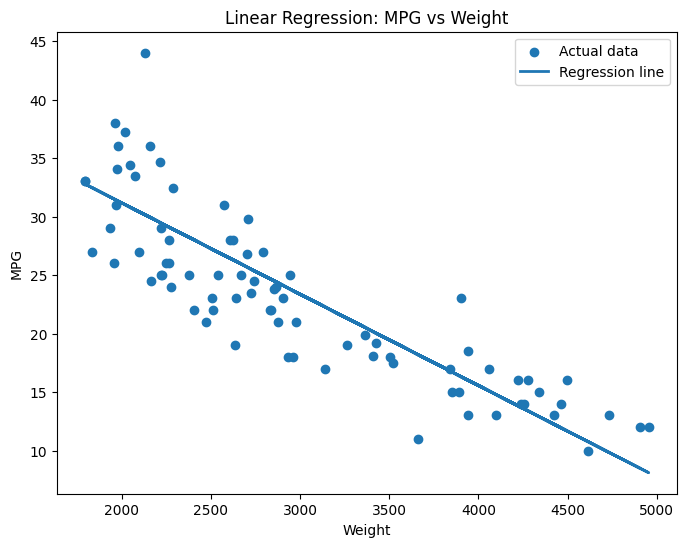

In [46]:
# Xw_train = X_train[["weight"]]
# Xw_test = X_test[["weight"]]

# lin_model = LinearRegression()
# lin_model.fit(Xw_train, y_train)

# y_pred = lin_model.predict(Xw_test)

# # Metrics
# mse = mean_squared_error(y_test, y_pred)
# mae = mean_absolute_error(y_test, y_pred)

# r2 = lin_model.score(Xw_test, y_test)

# print("R²:", r2)
# print("MAE:", mae)
# print("MSE:", mse)



# Load dataset
df = pd.read_csv("Auto.csv")

# Select columns
df = df[['weight', 'mpg']].dropna()

# Define variables
X = df[['weight']]
y = df['mpg']

# Split into training and test set
Xw_train, Xw_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create and fit model
lin_model = LinearRegression()
lin_model.fit(Xw_train, y_train)

# Predictions
y_pred = lin_model.predict(Xw_test)

# Calculate R² using .score()
r2 = lin_model.score(Xw_test, y_test)

# Calculate MSE
mse = mean_squared_error(y_test, y_pred)

# Print results
print(f"MPG = {lin_model.intercept_:.4f} + ({lin_model.coef_[0]:.6f} × weight)")
print(f"R² = {r2:.4f}")
print(f"MSE = {mse:.4f}")

# Plot
plt.figure(figsize=(8,6))
plt.scatter(Xw_test, y_test, label="Actual data")
plt.plot(Xw_test, y_pred, linewidth=2, label="Regression line")

plt.xlabel("Weight")
plt.ylabel("MPG")
plt.title("Linear Regression: MPG vs Weight")
plt.legend()

plt.show()

R² toont hoeveel variatie in MPG wordt verklaard door het model.

MSE toont de gemiddelde fout van de voorspellingen.

Het linear regression model kan MPG redelijk voorspellen, maar het model is beperkt omdat de relatie mogelijk niet volledig lineair is.

##### Question 5: Create a model using polynomial regression. Make an educated guess on the degree of the function and plot the model. Calculate the $R^2$ and MSE. Compare this to the metrics of your linear regression model. Is there an improvement?

In [36]:
poly = PolynomialFeatures(degree=2)

Xw_train_poly = poly.fit_transform(Xw_train)
Xw_test_poly = poly.transform(Xw_test)

poly_model = LinearRegression()
poly_model.fit(Xw_train_poly, y_train)

y_pred_poly = poly_model.predict(Xw_test_poly)

mse_poly = mean_squared_error(y_test, y_pred_poly)
mae_poly = mean_absolute_error(y_test, y_pred_poly)

r2_poly = poly_model.score(Xw_test_poly, y_test)

print("R²:", r2_poly)
print("MAE:", mae_poly)
print("MSE:", mse_poly)

R²: 0.7554139494160395
MAE: 2.7988739891721837
MSE: 13.150522130757171


Polynomial regression werkt meestal beter dan linear regression omdat het gebogen relaties kan modelleren.

Als R² hoger is en MSE lager is, betekent dit dat polynomial regression betere voorspellingen maakt.

Dit toont dat de relatie tussen weight en MPG niet volledig lineair is.

## 3.4 Model evaluation

We already did some early model evaluating, but we can look for a better degree of our function to improve the model.

##### Question 6: Figure out what the best degree of the function is. Calculate the MSE for each degree on training and testing data and plot the values to figure out the best value. be careful of overfitting!

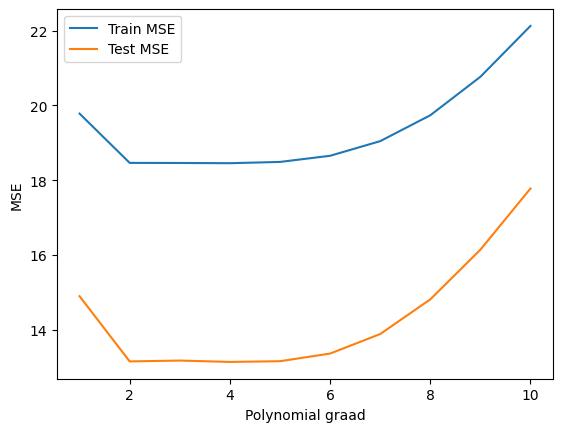

Beste degree (laagste Test MSE): 4


In [49]:
degrees = range(1, 11)

train_mse = []
test_mse = []
train_mae = []
test_mae = []

for d in degrees:
    poly = PolynomialFeatures(degree=d)
    Xt_train = poly.fit_transform(Xw_train)
    Xt_test = poly.transform(Xw_test)

    model = LinearRegression()
    model.fit(Xt_train, y_train)

    pred_train = model.predict(Xt_train)
    pred_test = model.predict(Xt_test)

    train_mse.append(mean_squared_error(y_train, pred_train))
    test_mse.append(mean_squared_error(y_test, pred_test))
    train_mae.append(mean_absolute_error(y_train, pred_train))
    test_mae.append(mean_absolute_error(y_test, pred_test))

plt.plot(degrees, train_mse, label="Train MSE")
plt.plot(degrees, test_mse, label="Test MSE")
plt.xlabel("Polynomial graad")
plt.ylabel("MSE")
plt.legend()
plt.show()

best_degree = degrees[np.argmin(test_mse)]
print("Beste degree (laagste Test MSE):", best_degree)

De beste polynomial graad is de graad met de laagste test MSE.

Als de graad te hoog wordt, ontstaat overfitting.

Het model leert dan de trainingsdata te goed en werkt slechter op nieuwe data.

## 3.5 Excercises

##### Question 1: See section 3.3

##### Question 2: See section 3.3

##### Question 3: See section 3.3

##### Question 4: See section 3.3

##### Question 5: See section 3.3

##### Question 6: See section 3.5

##### Question 7: A new car just came on the market with a weight of 2071 pounds. What MPG can we expect of this car?

In [51]:
best_poly = PolynomialFeatures(degree=best_degree)
best_model = LinearRegression()

best_model.fit(best_poly.fit_transform(Xw_train), y_train)

print("Voorspelde MPG voor weight=2071:", best_model.predict(best_poly.transform([[2071]])))

Voorspelde MPG voor weight=2071: [31.44961647]


c:\Users\chayb\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


Deze voorspelling gebruikt het beste polynomial regression model.

Het model schat de MPG van een auto met een gewicht van 2071 pounds.

##### Question 8: Have another look at the heatmap from section 3.3. Can you spot another variable that might bring an improvement to the model? Figure out the best degree and retrain the model with 'weight' and the added variabe. Calculate $R^2$ and the MSE. Did the model improve?

In [53]:
poly_multi = PolynomialFeatures(degree=2)

X_train_poly = poly_multi.fit_transform(X_train)
X_test_poly = poly_multi.transform(X_test)

multi_model = LinearRegression()
multi_model.fit(X_train_poly, y_train)

pred_multi = multi_model.predict(X_test_poly)

mse_multi = mean_squared_error(y_test, pred_multi)
r2_multi = multi_model.score(X_test_poly, y_test)

print("R²:", r2_multi)
print("MSE:", mse_multi)

R²: 0.8883106342682501
MSE: 6.005140000089311


##### Question 9: Figure out which columns give the best result. Retrain your models as many times as needed using different columns. figure out the best degree and calculate $R^2$ and the MSE. What is the best model you can achieve?

Het model met alle variabelen werkt beter omdat het meer informatie gebruikt.

MPG wordt beïnvloed door meerdere factoren zoals:

- weight
- horsepower
- displacement
- cylinders

Door meer relevante variabelen te gebruiken, worden de voorspellingen nauwkeuriger.